In [1]:
from build_design import build_design
%load_ext autoreload
%autoreload 2
import os
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"
os.environ["PMIX_MCA_gds"]="hash"

In [2]:
design = build_design()

In [5]:
from SQDMetal.PALACE.Capacitance_Simulation import PALACE_Capacitance_Simulation

#Eigenmode Simulation Options
user_defined_options = {
                "mesh_refinement": 0,                             #refines mesh in PALACE - essetially divides every mesh element in half
                "dielectric_material": "silicon",                  #choose dielectric material - 'silicon' or 'sapphire'
                "solver_order": 2,                                 #increasing solver order increases accuracy of simulation, but significantly increases sim time
                "solns_to_save": 3,                                #number of solutions to save for E-field visualization - ordered by the entries in the computed capacitance matrix
                "solver_tol": 1.0e-8,                              #error residual tolerance for iterative solver
                "solver_maxits": 200,                              #number of solver iterations
                "fillet_resolution":36,                            #number of vertices per quarter turn on a filleted path
                "palace_dir":"/home/ruiz/repo/spack/opt/spack/linux-zen3/palace-develop-blpbtxe43ne2or3yo7gou6ycmdwdxuzl/bin/palace",#"PATH/TO/PALACE/BINARY",
                #e.g.: "palace_dir":"/home/prasanna/spack/opt/spack/linux-ubuntu24.04-zen2/gcc-13.2.0/palace-0.12.0-q65qvkwsa5zglixv3rmm424wqsu3mcpv/bin/palace"
                "num_cpus" : 8
                }

#Create the Palace capacitance simulation
cap_sim = PALACE_Capacitance_Simulation(name = 'capacitance_sim',                                      #name of simulation
                                        metal_design = design,                                      #feed in qiskit metal design
                                        sim_parent_directory = "./",                                  #choose directory where mesh file, config file and HPC batch file will be saved
                                        mode = 'simPC',                                             #choose simulation mode 'HPC' or 'simPC'
                                        meshing = 'GMSH',                                           #choose meshing 'GMSH' or 'COMSOL'
                                        user_options = user_defined_options,                        #provide options chosen above
                                        create_files = True)                                        #create mesh, config and HPC batch files

#Add metallic elements from layer 1 in design file
cap_sim.add_metallic(1)

#Add ground plane to simulations
cap_sim.add_ground_plane()

Q1_NAME = 'Q1'
Q2_NAME = 'Q2'
COUPLER_NAME = 'coupler'

#Fine mesh the transmon cross qubit region
cap_sim.fine_mesh_components(
    [Q1_NAME, Q2_NAME], min_size=12e-6, max_size=80e-6, 
    taper_dist_min=10e-6, metals_only=False
    )
cap_sim.fine_mesh_components(
    [COUPLER_NAME], min_size=2e-6, max_size=80e-6, 
    taper_dist_min=5e-6, metals_only=False
    )
#This will prepare the mesh file and the config file
cap_sim.prepare_simulation()

In [6]:
cap_sim.open_mesh_gmsh()

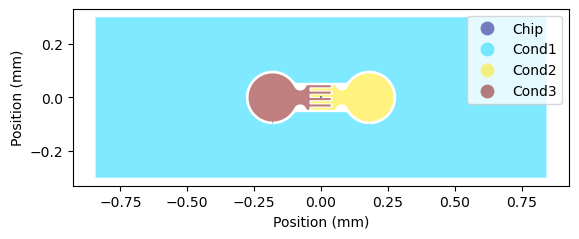

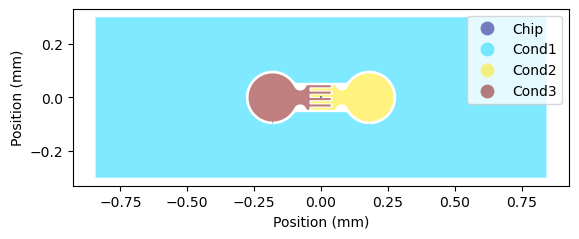

In [7]:
cap_sim.display_conductor_indices()

In [8]:
capMat = cap_sim.run()

>> /usr/bin/mpirun -n 8 /home/ruiz/repo/spack/opt/spack/linux-zen3/palace-develop-blpbtxe43ne2or3yo7gou6ycmdwdxuzl/bin/palace-x86_64.bin capacitance_sim.json

_____________     _______
_____   __   \____ __   /____ ____________
____   /_/  /  __ ` /  /  __ ` /  ___/  _ \
___   _____/  /_/  /  /  /_/  /  /__/  ___/
  /__/     \___,__/__/\___,__/\_____\_____/


--> Warning!
Output folder is not empty; program will overwrite content! (outputFiles)
Git changeset ID: 3b8c020
Running with 8 MPI processes
Device configuration: cpu
Memory configuration: host-std
libCEED backend: /cpu/self/xsmm/blocked

Added 936 boundary elements for material interfaces to the mesh

Characteristic length and time scales:
 Lc = 2.023e-03 m, tc = 6.749e-03 ns
Finished partitioning mesh into 8 subdomains

Mesh curvature order: 1
Mesh bounding box:
 (Xmin, Ymin, Zmin) = (-1.012e-03, -3.600e-04, -5.000e-04) m
 (Xmax, Ymax, Zmax) = (+1.012e-03, +3.600e-04, +5.000e-04) m

Parallel Mesh Stats:

                minimum

In [9]:
capMat

array([[ 4.96770533e-13, -8.10850307e-14, -8.10696214e-14],
       [-8.10850307e-14,  1.33416728e-13, -4.28999568e-14],
       [-8.10696214e-14, -4.28999568e-14,  1.33399933e-13]])